# 1. Profiling data mentah

Membaca 27 file AQMS, data kesehatan harian, dan tabel master untuk melihat ukuran data, satuan, status `qc_flag`, nilai yang tidak wajar, dan cakupan waktu. Ringkasannya disimpan ke `hasil/01_profiling_data.xlsx`, gambarnya ke `hasil/gambar/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
%matplotlib inline

In [2]:
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW = "../data/raw/"
OUT = "../hasil/"
GAMBAR = OUT + "gambar/"
POL = ["pm25", "pm10", "so2", "co", "o3", "no2"]
MET = ["temperature_c", "humidity_pct", "wind_speed_ms", "wind_direction_deg"]

In [3]:
sites = pd.read_csv(RAW + "sites.csv")
sensors = pd.read_csv(RAW + "sensors.csv")
hospitals = pd.read_csv(RAW + "hospitals.csv")
meta_dates = pd.read_csv(RAW + "metadata_dates.csv")

profil, qc_rows, contoh_sampah = [], [], []

In [4]:
for f in sorted(glob.glob(RAW + "*_AQMS.csv")):
    kode = re.search(r"([A-Z0-9]+-\d+)_", f).group(1)
    d = pd.read_csv(f, dtype=str)
    satuan = "ppm" if "pm25_ppm" in d.columns else "ug/m3"
    suf = "_ppm" if satuan == "ppm" else "_ug_m3"
    ts = pd.to_datetime(d["timestamp_start"], format="mixed")
    jam = ts.dt.round("h")
    selisih = ts.diff().dropna()
    resolusi = ", ".join(f"{int(k.total_seconds() // 60)} mnt ({v})" for k, v in selisih.value_counts().head(2).items())

    teks_sampah = 0
    for c in [p + suf for p in POL] + MET:
        x = d[c].dropna()
        bad = x[pd.to_numeric(x, errors="coerce").isna()]
        teks_sampah += len(bad)
        if len(bad):
            contoh_sampah += [{"stasiun": kode, "kolom": c, "nilai": k, "jumlah": v} for k, v in bad.value_counts().items()]

    pm = pd.to_numeric(d["pm25" + suf], errors="coerce")
    periode_ok = jam[(jam >= "2024-01-01") & (jam <= "2026-10-14 23:00")]
    grid = pd.date_range("2024-01-01", "2026-10-14 23:00", freq="h")

    profil.append({
        "stasiun": kode,
        "sensor_id": d["sensor_id"].iloc[0],
        "jumlah_baris": len(d),
        "awal": ts.min(),
        "akhir": ts.max(),
        "baris_tahun_1970": int((ts.dt.year == 1970).sum()),
        "satuan": satuan,
        "resolusi_dominan": resolusi,
        "offset_maks_menit": round((ts - jam).abs().max().total_seconds() / 60, 1),
        "jam_hilang": int(grid.difference(periode_ok).size),
        "pct_valid": round((d["qc_flag"] == "VALID").mean() * 100, 1),
        "nilai_teks_sampah": teks_sampah,
        "pm25_kosong_pct": round(pm.isna().mean() * 100, 1),
        "pm25_negatif": int((pm < 0).sum()),
        "pm25_9999": int((pm == -9999).sum()),
        "pm25_999": int((pm == 999).sum()),
        "pm25_inf": int(np.isinf(pm).sum()),
        "pm25_median": round(pm.replace([np.inf, -np.inf], np.nan).median(), 4),
        "pm25_p99": round(pm.replace([np.inf, -np.inf], np.nan).quantile(0.99), 4),
        "pm25_maks": pm.replace([np.inf, -np.inf], np.nan).max(),
    })
    qc = d["qc_flag"].value_counts(normalize=True).mul(100).round(2)
    qc_rows.append(qc.rename(kode))

In [5]:
profil = pd.DataFrame(profil)
qc_tab = pd.DataFrame(qc_rows).fillna(0)
qc_tab = qc_tab[["VALID"] + [c for c in qc_tab.columns if c != "VALID"]]
sampah = pd.DataFrame(contoh_sampah)

profil = profil.merge(
    sensors[["sensor_id", "location_id", "status_operasional"]], on="sensor_id", how="left"
).merge(sites[["location_id", "provinsi", "site_type", "baseline_pm25"]], on="location_id", how="left")

In [6]:
h = pd.read_csv(RAW + "HLT-01_health_outcomes_daily.csv")
h["date"] = pd.to_datetime(h["date"])
outcome = ["resp_admissions_under5", "resp_admissions_over60", "asthma_emergency_cases",
           "copd_admissions", "resp", "cvd", "death"]
hp = h.groupby("hospital_id").agg(
    jumlah_hari=("date", "size"), awal=("date", "min"), akhir=("date", "max"),
    duplikat=("date", lambda s: int(s.duplicated().sum())),
).reset_index()
hp["hari_hilang"] = (hp["akhir"] - hp["awal"]).dt.days + 1 - hp["jumlah_hari"] + hp["duplikat"]
for o in outcome:
    hp[o + "_rata2"] = h.groupby("hospital_id")[o].mean().round(2).values
h_stat = h[outcome + ["temp_c", "dptp_c", "rhum_pct"]].describe().T.round(2)
h_stat["negatif"] = (h[outcome + ["temp_c", "dptp_c", "rhum_pct"]] < 0).sum()
h_stat["kosong"] = h[outcome + ["temp_c", "dptp_c", "rhum_pct"]].isna().sum()
sub = h["resp_admissions_under5"] + h["resp_admissions_over60"]
cek_logika = pd.Series({
    "baris_resp_lebih_kecil_dari_balita_plus_lansia": int((h["resp"] < sub).sum()),
    "baris_resp_lebih_kecil_dari_balita": int((h["resp"] < h["resp_admissions_under5"]).sum()),
    "baris_tanggal_2023": int((h["date"] < "2024-01-01").sum()),
    "hari_dow_tidak_cocok": int((h["date"].dt.day_name() != h["dow"]).sum()),
})

In [7]:
cek_master = pd.Series({
    "sensor_di_file_tidak_ada_di_sensors": len(set(profil["sensor_id"]) - set(sensors["sensor_id"])),
    "location_sensors_tidak_ada_di_sites": len(set(sensors["location_id"]) - set(sites["location_id"])),
    "rs_di_kesehatan_tidak_ada_di_hospitals": len(set(h["hospital_id"]) - set(hospitals["hospital_id"])),
    "provinsi_sites_vs_hospitals_beda": len(set(sites["provinsi"]) ^ set(hospitals["provinsi"])),
    "metadata_dates_tidak_standar": int((meta_dates["date_start"] != "2024-01-01 00:00:00").sum()),
    "kapasitas_tt_kosong": int(hospitals["kapasitas_tempat_tidur"].isna().sum()),
})

In [8]:
with pd.ExcelWriter(OUT + "01_profiling_data.xlsx") as w:
    profil.to_excel(w, sheet_name="profil_aqms", index=False)
    qc_tab.to_excel(w, sheet_name="distribusi_qc_flag_pct")
    sampah.to_excel(w, sheet_name="contoh_nilai_sampah", index=False)
    hp.to_excel(w, sheet_name="profil_kesehatan_per_rs", index=False)
    h_stat.to_excel(w, sheet_name="statistik_kesehatan")
    cek_logika.to_frame("jumlah").to_excel(w, sheet_name="cek_logika_kesehatan")
    cek_master.to_frame("jumlah").to_excel(w, sheet_name="cek_tabel_master")

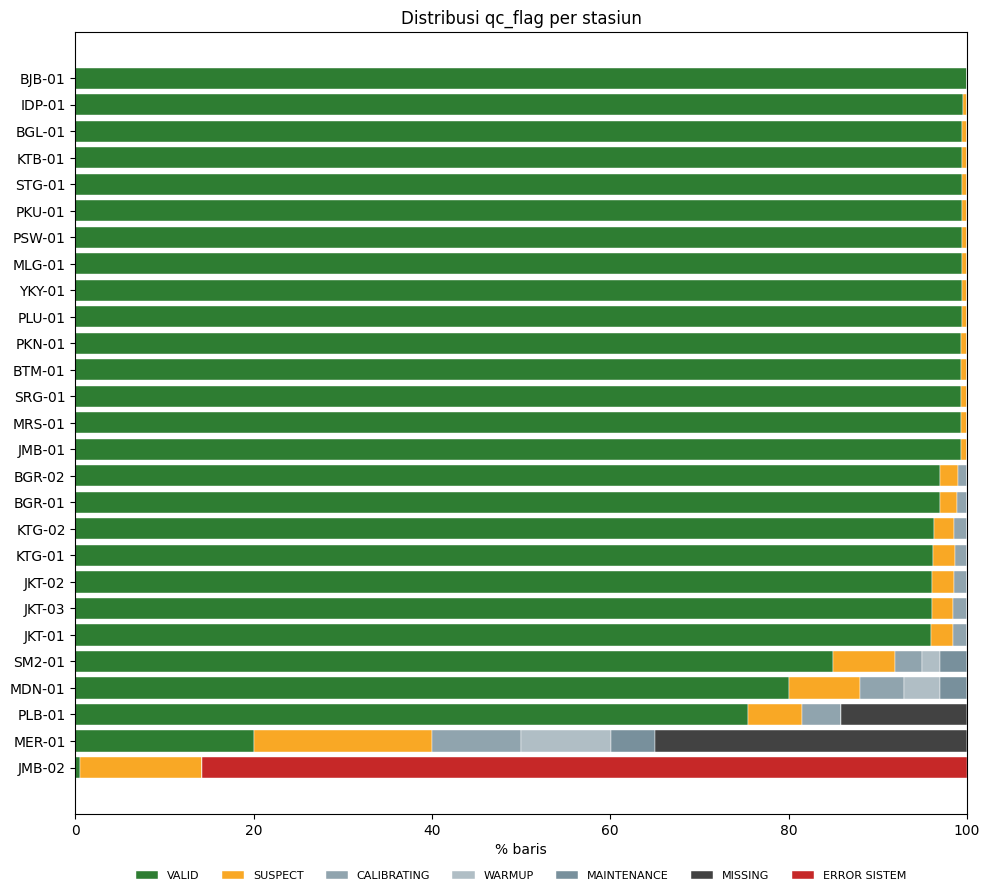

In [9]:
warna = {"VALID": "#2e7d32", "SUSPECT": "#f9a825", "CALIBRATING": "#90a4ae", "WARMUP": "#b0bec5",
         "MAINTENANCE": "#78909c", "MISSING": "#424242"}
err = [c for c in qc_tab.columns if c not in warna]
qc_plot = qc_tab.drop(columns=err).assign(**{"ERROR SISTEM": qc_tab[err].sum(axis=1)})
urut = qc_plot.sort_values("VALID")
fig, ax = plt.subplots(figsize=(10, 9))
kiri = np.zeros(len(urut))
for c in urut.columns:
    ax.barh(urut.index, urut[c], left=kiri, color=warna.get(c, "#c62828"), label=c, edgecolor="white", linewidth=0.3)
    kiri += urut[c].values
ax.set_xlabel("% baris")
ax.set_title("Distribusi qc_flag per stasiun")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), fontsize=8, ncol=7, frameon=False)
ax.set_xlim(0, 100)
plt.tight_layout()
plt.savefig(GAMBAR + "01_qc_flag_per_stasiun.png", dpi=150)
plt.show()

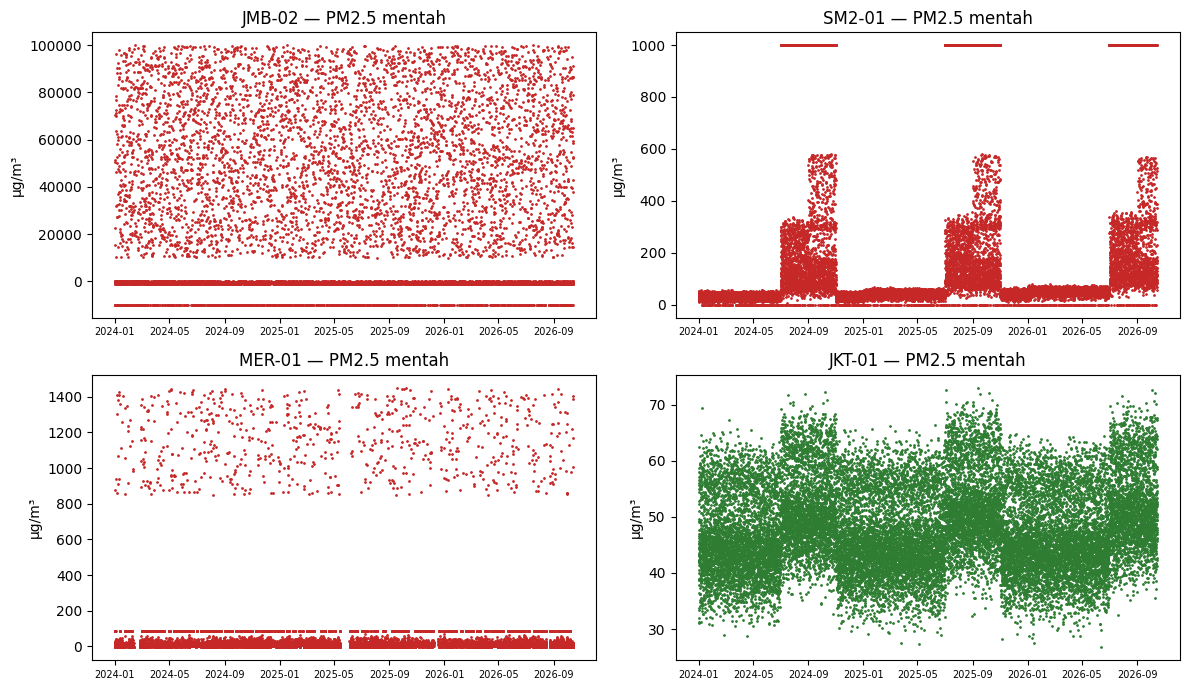

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (kode, f) in zip(axes.flat, [("JMB-02", "JMB-02_MuaroJambi"), ("SM2-01", "SM2-01_Samarinda"),
                                      ("MER-01", "MER-01_Merauke"), ("JKT-01", "JKT-01_Gambir")]):
    d = pd.read_csv(RAW + f + "_AQMS.csv", dtype=str)
    t = pd.to_datetime(d["timestamp_start"], format="mixed")
    x = pd.to_numeric(d["pm25_ug_m3"], errors="coerce").replace([np.inf, -np.inf], np.nan)
    ax.scatter(t[t.dt.year > 2000], x[t.dt.year > 2000], s=1, color="#c62828" if kode != "JKT-01" else "#2e7d32")
    ax.set_title(f"{kode} — PM2.5 mentah")
    ax.set_ylabel("µg/m³")
    ax.tick_params(axis="x", labelsize=7)
plt.tight_layout()
plt.savefig(GAMBAR + "01_contoh_data_bermasalah.png", dpi=150)
plt.show()

In [11]:
print(profil.drop(columns=["location_id"]).to_string())
print(qc_tab.round(1).to_string())
print(hp.to_string())
print(h_stat.to_string())
print(cek_logika.to_string())
print(cek_master.to_string())

   stasiun sensor_id  jumlah_baris                    awal                   akhir  baris_tahun_1970 satuan                resolusi_dominan  offset_maks_menit  jam_hilang  pct_valid  nilai_teks_sampah  pm25_kosong_pct  pm25_negatif  pm25_9999  pm25_999  pm25_inf  pm25_median    pm25_p99   pm25_maks status_operasional            provinsi                            site_type  baseline_pm25
0   BGL-01  SENS-014         24432 2024-01-01 00:02:10.000 2026-10-14 23:02:10.000                 0  ug/m3                  60 mnt (24431)                2.2           0       99.5                  0              0.0             0          0         0         0      25.1000     49.6000     65.0000             Active            Bengkulu             Urban Coastal Background           25.0
1   BGR-01  SENS-006         24432 2024-01-01 00:00:00.000 2026-10-14 23:00:00.000                 0  ug/m3                  60 mnt (24431)                0.0           0       97.0                  0              0.0 